# 03 · Missing values and scaling

[Guide](../README.md) | [Previous](02_Baselines_and_Validation.ipynb) | [Next](04_Categorical_Encoding.ipynb)

## 1. What problem are we solving?

How should we handle blanks and numerical inputs measured on different scales?

## 2. Why does it matter?

Dropping data loses information; extreme values and units can influence a linear model.

## 3. Key concepts

| Term | Simple meaning |
|---|---|
| Imputation | Replace a blank using a value learned from the training rows. |
| Standard scaling | Subtract the training mean and divide by the training standard deviation. |
| Robust scaling | Subtract the training median and divide by the middle-half spread (IQR). Extremes affect it less. |
| Why scale? | Numerical units affect distance-based and linear models. Make capacity and foot use comparable; trees usually do not need scaling. |
| Missing indicator | An extra 0/1 column records whether the original value was absent. Filling alone loses that fact; this is an explained alternative, not an added scored candidate. |
| Mean / median / mode | Average / middle value / most frequent value; they fill different kinds of blanks. |
| Standard deviation / IQR | Two measures of spread: deviation around the mean / the width of the middle 50% (interquartile range). |
| FunctionSampler | Apply a row-filtering function during fitting only; do not remove evaluation rows. |
| Pipeline notation | `clone` copies unfitted settings; `step__setting` changes one pipeline setting. Earlier steps stay fixed during a comparison. |

## 4. Intuitive example

For illustrative minutes `[70, blank, 90]`, the training median is 80. Filling gives `[70, 80, 90]`; a missing indicator would be `[0, 1, 0]`. Dropping the incomplete row keeps two records instead. The missing indicator is explained, not included in the four-method comparison below.

## 5. Methods to compare

| Choice | What changes | Trade-off |
|---|---|---|
| Drop incomplete training rows | Fit on complete records | Simple; loses rows and can bias the sample |
| Drop incomplete columns | Remove the six inputs identified as incomplete | Keeps rows; loses potentially useful measurements |
| Mean + mode | Fill numbers with averages and categories with their most common value | Keeps rows; numerical extremes affect the mean |
| Median + mode | Fill numbers with middle values, categories with the mode | Less sensitive to extremes; does not preserve all relationships |
| No scaling | Keep original numerical units | Simple; large units may dominate some models |
| Standard scaling | Use training mean and standard deviation | Comparable scales; sensitive to extremes |
| Robust scaling | Use training median and IQR | Less sensitive, not immune, to extremes |

First choose missing handling; then compare scales while keeping that choice fixed. Row removal applies only during fitting. All candidates still predict every evaluation row, filling future blanks when needed.

## 6. What we retained from previous notebooks

**Prior knowledge:** From 02: a basic-imputation/encoding Logistic Regression baseline achieved CV F1 ≈0.851.

**Carry forward:** Use the same train-only folds so improvements can be compared with baseline fairly.

## 7. Setup

**Reusable setup — run this cell, then skip to the lesson.** You do not need to study all these lines now: they load the data and rebuild earlier steps so this notebook works on its own. Revisit the earlier lessons for explanations.

Change `DATA_DIR` for your runtime. The cell starts collapsed where the editor supports it; GitHub may show it expanded. `X` contains inputs; `y` contains known answers. Learned preparation stays inside training folds.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 3)

# Change this one folder on Kaggle or Colab (see the guide).
DATA_DIR = "../data"
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
print("Train:", train.shape, "Test:", test.shape)

# Split train.csv: 80% for training, 20% for a separate validation check.
training_data, validation_data = train_test_split(
    train, test_size=0.20, stratify=train["is_scored"], random_state=2026
)
training_data = training_data.reset_index(drop=True)

# IDs identify rows; they do not describe how a penalty was taken.
id_columns = ["id", "kicker_id", "keeper_id", "match_id"]
X = training_data.drop(columns=id_columns + ["is_scored"])
y = training_data["is_scored"]

from sklearn.base import clone
from sklearn.compose import make_column_selector
from sklearn.preprocessing import FunctionTransformer, RobustScaler
from imblearn import FunctionSampler
from imblearn.pipeline import Pipeline

numbers = Pipeline([("fill", SimpleImputer(strategy='median')), ("scale", StandardScaler())])
categories = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocess = ColumnTransformer([
    ("numbers", numbers, make_column_selector(dtype_include="number")),
    ("categories", categories, make_column_selector(dtype_exclude="number")),
])

pipeline = Pipeline([
    ("missing_rows", "passthrough"),
    ("columns", "passthrough"),
    ("prepare", preprocess),
    ("model", LogisticRegression(solver="liblinear", max_iter=1000, random_state=42)),
])

# Each fold trains on two parts and predicts the third, unseen part.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def compare(models, X, y):
    rows = []
    for name, model in models.items():
        scores = cross_validate(model, X, y, cv=cv, scoring=["f1", "accuracy", "roc_auc"])
        rows.append([name, scores["test_f1"].mean(), scores["test_f1"].std(),
                     scores["test_accuracy"].mean(), scores["test_roc_auc"].mean()])
    columns = ["method", "F1", "F1 spread", "accuracy", "ROC-AUC"]
    return pd.DataFrame(rows, columns=columns).sort_values("F1", ascending=False)

Train: (20000, 20) Test: (6000, 19)


## 8. Experiments

Run the topic-specific steps below. Saved experimental outputs are retained from the earlier runs; regrouping setup does not create a new evaluation.

### Implement this lesson's methods

These are the new alternatives for this topic; the reusable pipeline is already in Setup. Row-changing methods run only during fitting.

In [6]:
def remove_incomplete_rows(X, y):
    keep = ~X.isna().any(axis=1)
    return X.loc[keep], y[keep]

In [7]:
def remove_incomplete_columns(data):
    # Fixed list of columns found incomplete in EDA; no validation statistics are used.
    columns = ["jersey_color", "referee_strictness", "stadium_capacity",
               "temperature", "weather_humidity", "minute_taken"]
    return data.drop(columns=columns, errors="ignore")

### 1. What is missing?
`isna().sum()` counts empty cells; it does not fill them. `dropna()` removes incomplete rows.
A **mean** is the average; a **median** is the middle value; a **mode** is the most common value.

In [11]:
display(X.isna().sum().sort_values(ascending=False))
print("Training rows lost by dropping incomplete rows:", X.isna().any(axis=1).sum())
print("Columns lost by dropping incomplete columns:", X.isna().any().sum())

jersey_color                      525
weather_humidity                  491
temperature                       470
referee_strictness                457
stadium_capacity                  428
minute_taken                      163
match_type                          0
home_or_away                        0
current_score_diff                  0
pitch_condition                     0
crowd_behind_goal                   0
player_last5_scored_percent         0
goalkeeper_last5_saved_percent      0
strong_foot_usage                   0
weak_foot_usage                     0
dtype: int64

Training rows lost by dropping incomplete rows: 2364
Columns lost by dropping incomplete columns: 6


In [12]:
missing_models = {
    "Drop incomplete training rows": clone(pipeline).set_params(missing_rows=FunctionSampler(func=remove_incomplete_rows, validate=False)),
    "Drop incomplete columns": clone(pipeline).set_params(columns=FunctionTransformer(remove_incomplete_columns)),
    "Mean + mode": clone(pipeline).set_params(prepare__numbers__fill__strategy="mean"),
    "Median + mode": clone(pipeline),
}

,method,F1,F1 spread,accuracy,ROC-AUC
0,Drop incomplete training rows,0.852,0.003,0.867,0.941
3,Median + mode,0.851,0.003,0.866,0.941
2,Mean + mode,0.851,0.003,0.866,0.941
1,Drop incomplete columns,0.845,0.002,0.861,0.939


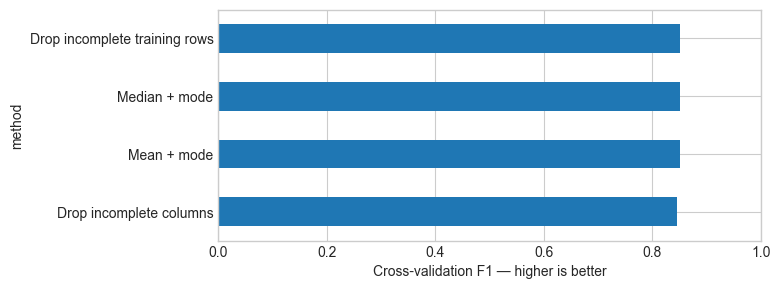

Continue with: Drop incomplete training rows


In [13]:
missing_results = compare(missing_models, X, y)
display(missing_results.round(4))
missing_results.set_index("method")["F1"].sort_values().plot.barh(figsize=(7, 3))
plt.xlabel("Cross-validation F1 — higher is better")
plt.xlim(0, 1)
plt.show()
print("Continue with:", missing_results.iloc[0]["method"])

**Decision:** continue with the highest-F1 tested method; equal scores keep the first listed method.
We judge all methods on the same unseen rows, so dropping data is not rewarded by avoiding hard questions.

**Other alternatives:** KNN fills from similar rows (needs sensible distances); iterative imputation predicts
missing columns from other inputs (more computation); a missing-value flag preserves evidence that a value was absent.

In [14]:
X_fit, X_example = train_test_split(X, test_size=0.25, random_state=42)
example = X_example.loc[X_example["stadium_capacity"].isna(), ["stadium_capacity"]].head()
example["training mean"] = X_fit["stadium_capacity"].mean()
example["training median"] = X_fit["stadium_capacity"].median()
display(example)

,stadium_capacity,training mean,training median
2929,NaN,56801.162,55947.0
10506,NaN,56801.162,55947.0
14391,NaN,56801.162,55947.0
9629,NaN,56801.162,55947.0
7691,NaN,56801.162,55947.0


### 2. Scaling is a separate choice
**Standard scaling** subtracts the mean and divides by spread. **Robust scaling** uses the median
and middle-half spread, reducing sensitivity to extremes. Trees usually do not need scaling;
linear and distance-based models often do. Keep the winning missing-value rule unchanged below.

### Before the scaling comparison

For illustrative complete values `[10, 20, 30]`, standard scaling uses mean 20 and standard deviation about 8.16, producing `[-1.225, 0, 1.225]`. Robust scaling uses median 20 and IQR 10, producing `[-1, 0, 1]`.

Now replace 30 with 1,000: the mean and standard deviation move strongly. Median/IQR are generally less sensitive to extremes, not immune to them. Keep the chosen missing-value rule fixed while comparing scales.

In [15]:
selected_missing = missing_results.iloc[0]["method"]
pipeline = clone(missing_models[selected_missing])
scaling_models = {
    "No scaling": clone(pipeline).set_params(prepare__numbers__scale="passthrough"),
    "Standard scaling": clone(pipeline).set_params(prepare__numbers__scale=StandardScaler()),
    "Robust scaling": clone(pipeline).set_params(prepare__numbers__scale=RobustScaler()),
}

,method,F1,F1 spread,accuracy,ROC-AUC
2,Robust scaling,0.852,0.003,0.867,0.941
1,Standard scaling,0.852,0.003,0.867,0.941
0,No scaling,0.830,0.002,0.849,0.919


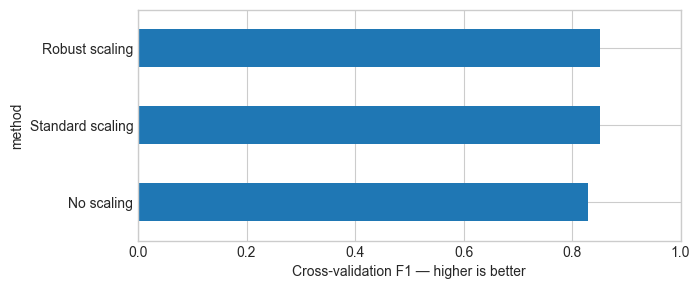

Continue with: Robust scaling


In [16]:
scaling_results = compare(scaling_models, X, y)
display(scaling_results.round(4))
scaling_results.set_index("method")["F1"].sort_values().plot.barh(figsize=(7, 3))
plt.xlabel("Cross-validation F1 — higher is better")
plt.xlim(0, 1)
plt.show()
print("Continue with:", scaling_results.iloc[0]["method"])

**Other alternatives:** min–max scaling maps a range to 0–1 but is sensitive to extremes.
A log transform compresses large positive values; it is not the same as standardization and is not needed everywhere.
Lesson 05 tests `log_capacity` as an environment feature rather than applying logs to every column.

### Example: the same capacities on three scales
Fit the scales using complete training measurements. Units change, not which stadium is larger.
This illustration does not choose a different strategy.

In [17]:
capacities = X[["stadium_capacity"]].dropna()
scaled_example = capacities.head().copy()
scaled_example["standard scale"] = StandardScaler().fit(capacities).transform(capacities.head()).ravel()
scaled_example["robust scale"] = RobustScaler().fit(capacities).transform(capacities.head()).ravel()
display(scaled_example)

,stadium_capacity,standard scale,robust scale
0,59036.0,0.077,0.061
1,66767.0,0.354,0.230
2,38915.0,-0.646,-0.380
4,53037.0,-0.139,-0.070
5,115257.0,2.096,1.292


## 9. Results and decision

| Question | Answer |
|---|---|
| What did we compare? | Drop rows, drop columns, mean/mode, median/mode; then no scaling, StandardScaler, and RobustScaler. |
| Which performed best? | Drop incomplete training rows (CV F1 0.8520); Robust scaling (CV F1 0.8520) |
| Why did we choose it? | At this stage dropping incomplete training rows scores slightly higher; robust scaling limits the influence of extremes on the linear baseline. |
| What are its limitations? | Dropped rows may bias the sample; tiny score gaps are not proof. Later Notebook 16 rechecks missing handling with the stronger model and keeps/imputes rows. |
| What continues to the next notebook? | Drop incomplete training rows + robust scaling; training-fitted median/mode filling remains available for future missing inputs. |

## 10. Key takeaways and next step

- Fit filling and scaling values on training rows only; never drop hard evaluation rows.
- The best missing-value choice can change with the learner; a tiny score gap is not strong evidence.

Next: [04 Categorical Encoding](04_Categorical_Encoding.ipynb).